In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

In [49]:
import torch
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torch.optim as optim
from torch.utils.data import random_split

import numpy as np 
import matplotlib.pyplot as plt 

# Downloading data 

Run the code block below to download all the data you need for task 1 and 2 (took me like 20 minutes for the CIFAR10 datasets, but the other ones were pretty quick)

To (un)comment multiple lines: CTRL + /

In [ ]:
# # Download the CIFAR datasets
# cifar10_train = datasets.CIFAR10(root = "./data", train = True, download = True)
# cifar10_test = datasets.CIFAR10(root = "./data", train = False, download = True)

# # Download Fashion-MNIST datasets
# fashion_train = datasets.FashionMNIST(root = "./data", train = True, download = True)
# fashion_test = datasets.FashionMNIST(root = "./data", train = False, download = True)

# # Download time datasets (Task 2)
# import os
# from urllib.request import urlretrieve
# import zipfile

# urls = ["https://surfdrive.surf.nl/public.php/dav/files/Nznt5c48Mzlb2HY/A1_data_75.zip", 
#         "https://surfdrive.surf.nl/public.php/dav/files/Nznt5c48Mzlb2HY/A1_data_150.zip"]

# target_folder = "./data"

# for url in urls:
#     file_name = os.path.basename(url)
#     full_path = os.path.join(target_folder, file_name)

#     # Create separate folder for each dataset 
#     dataset_name = os.path.splitext(file_name)[0]
#     extract_folder = os.path.join(target_folder, dataset_name)
#     os.makedirs(extract_folder, exist_ok = True)

#     # Download zip file
#     urlretrieve(url, full_path)

#     # Extract zip file
#     with zipfile.ZipFile(full_path, "r") as zip_ref:
#         zip_ref.extractall(extract_folder)

#     # Remove ZIP file
#     os.remove(full_path)

100%|██████████| 170498071/170498071 [21:31<00:00, 132051.66it/s]


Extracting ./data/cifar-10-python.tar.gz to ./data
Files already downloaded and verified


# Task 1

## Fashion MNIST

### Processing

**Loading data: train, validation, test**

In [44]:
transform = transforms.Compose([
    transforms.ToTensor() # Tbh I still don't know what tensors do 
])

# Load the data 
fashion_train_all = datasets.FashionMNIST(root = "./data", train = True, download = True, transform = transform)
fashion_test = datasets.FashionMNIST(root = "./data", train = False, download = True, transform = transform)

# Split 10% of training data for the validation set
train_size = int(0.9 * len(fashion_train_all))
validation_size = len(fashion_train_all) - train_size

fashion_train, fashion_validation = random_split(
    fashion_train_all,
    [train_size, validation_size],
    generator = torch.Generator().manual_seed(67) # (our group number)
)

**Visualise**

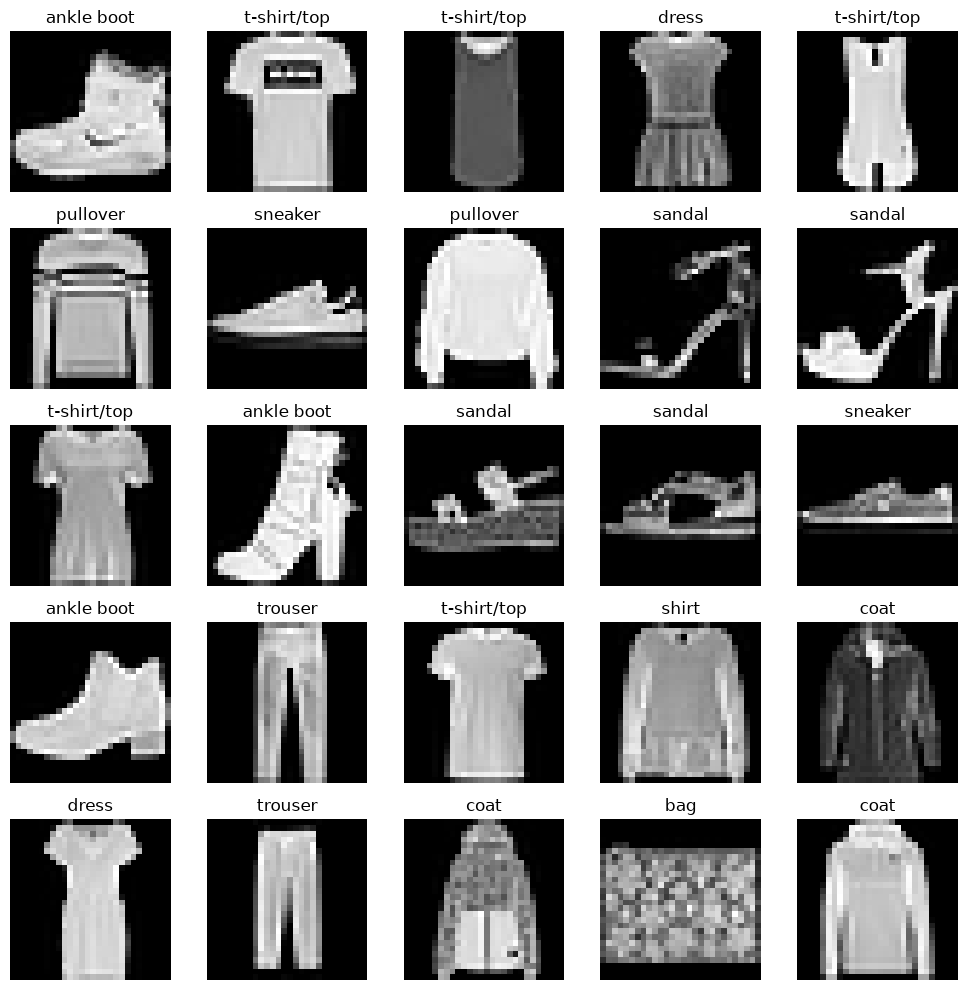

In [41]:
# Define class names
fashion_names = {
    0: "t-shirt/top",
    1: "trouser",
    2: "pullover",
    3: "dress",
    4: "coat",
    5: "sandal",
    6: "shirt",
    7: "sneaker",
    8: "bag",
    9: "ankle boot"
}

# Visualise 
n = 5

fig, ax = plt.subplots(n, n, figsize = (10, 10))

for i in range(n):
    for j in range(n):
        image, label = fashion_train[i * n + j] 
        image_np = image.numpy().squeeze() # Convert image tensor to numpy array
        ax[i, j].imshow(image_np, cmap = "gray")
        ax[i, j].axis("off")
        ax[i, j].set_title(fashion_names[label])
plt.tight_layout()
plt.show()

**Dataloader** (for more efficient processing)

Shuffling doesn't really matter for the validation and test set. Only changes the order of things, but if you take the average it should be the same regardless of order

In [47]:
batch_size = 64 # One stack because why not 

fashion_train_loader = DataLoader(fashion_train, batch_size = batch_size, shuffle = True)
fashion_validation_loader = DataLoader(fashion_validation, batch_size = batch_size, shuffle = False)
fashion_test_loader = DataLoader(fashion_test, batch_size = batch_size, shuffle = False)

### Multi-Layer Perceptron (MLP) 

NOTES
* The amount of hidden layers and nodes I choose for them feels rather arbitrary. I just followed along with the values from the tutorial but idk if there would be a good reasoning for it

HYPERPARAMETERS
* activation: nn.ReLu, nn.LeakyReLU, nn.GELU ... 

In [58]:
# Create model 
class MLP(nn.Module):
    def __init__(
            self, 
            hidden_dims = (128, 64),
            activation = nn.ReLU,
            dropout = 0.0,
            initialization = None,
            optimizer_name = None,
            learning_rate = 0.001,
            momentum = 0.0,
            weight_decay = 0.1
    ):
        super().__init__() 

        # Create the layers 
        layers = [nn.Flatten()]
        input_size = 28 * 28 # Amount of pixels we have

        for hidden_size in hidden_dims:
            layers.append(nn.Linear(input_size, hidden_size))
            layers.append(activation())

            if dropout > 0:
                layers.append(nn.Dropout(dropout))

            input_size = hidden_size # Change input size, so each layer connects to the next one

        layers.append(nn.Linear(input_size, 10)) # Last layer (output: 10, because we have 10 classes)

        # Combine all our layers into a network
        self.network = nn.Sequential(*layers)

        # Initialize weights
        if initialization is not None: 
            self.parameter_initializations(initialization)

        # Create optimizer
        if optimizer_name is not None:
            self.optimizer = self.create_optimizer(
                optimizer_name,
                learning_rate,
                weight_decay,
                momentum
            )

def parameter_initializations(self, idk):
    # TODO
    pass

def create_optimizer(self, name, learning_rate, weight_decay, momentum, ):
    optimizer_name = {
        "SGD": optim.SGD,
        "Adam": optim.Adam,
        "AdamW": optim.AdamW
    }

    args = {"lr": learning_rate, "weight_decay": weight_decay}

    if name == "SGD": 
        args["momentum"] = momentum

    # Return the optimizer
    return optimizer_name[name](self.parameters(), **args)


In [59]:
# Initialise model
model = MLP(
    # Architecture 
    hidden_dims = [128, 64],

    # Activation
    activation = nn.ReLU, # nn.ReLU, nn.LeakyReLU, nn.GELU
    # Also more options (see Session 3 slide 10)
    # nn.Signmoid, nn.Tahn, nn.PReLU, nn.Softplus, nn.SiLU, nn.ELU, nn.SELU 

    # Weight initialization
    initialization = None,

    # Optimizer
    optimizer_name = None, # "SGD", "Adam", "AdamW"
    learning_rate = 0.001, 
    momentum = 0.0,

    # Regularization
    dropout = 0.0,
    weight_decay = 0.0, # (also part of our optimizer)

    # Training epochs
    #epochs = 10
)

### Convolutional Neural Network (CNN)

## CIFAR-10

### Multi-Layer Perceptron (MLP)

### Convolutional Neural Network (CNN)